# Creating linear kernel SVM

Let’s create a Linear Kernel SVM using the sklearn library of Python and the Iris Dataset that can be found in the dataset library of Python.

Linear Kernel is used when the data is Linearly separable, that is, it can be separated using a single Line. It is one of the most common kernels to be used. It is mostly used when there are a Large number of Features in a particular Data Set.

##### Advantages of using Linear Kernel:
<ol>
    <li>Training a SVM with a Linear Kernel is Faster than with any other Kernel.</li>

<li>When training a SVM with a Linear Kernel, only the optimisation of the C Regularisation parameter is required. On the other hand, when training with other kernels, there is a need to optimise the γ parameter which means that performing a grid search will usually take more time.</li>
</ol>
    

In [1]:
# Import the Libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn import svm, datasets
  
# Import some Data from the iris Data Set
iris = datasets.load_iris()
  
# Take only the first two features of Data.
# To avoid the slicing, Two-Dim Dataset can be used
  
X = iris.data[:, :2]
y = iris.target
  
# C is the SVM regularization parameter
C = 1.0 
  
# Create an Instance of SVM and Fit out the data.
# Data is not scaled so as to be able to plot the support vectors
svc = svm.SVC(kernel ='linear', C = 1).fit(X, y)
  

### Visualisation 

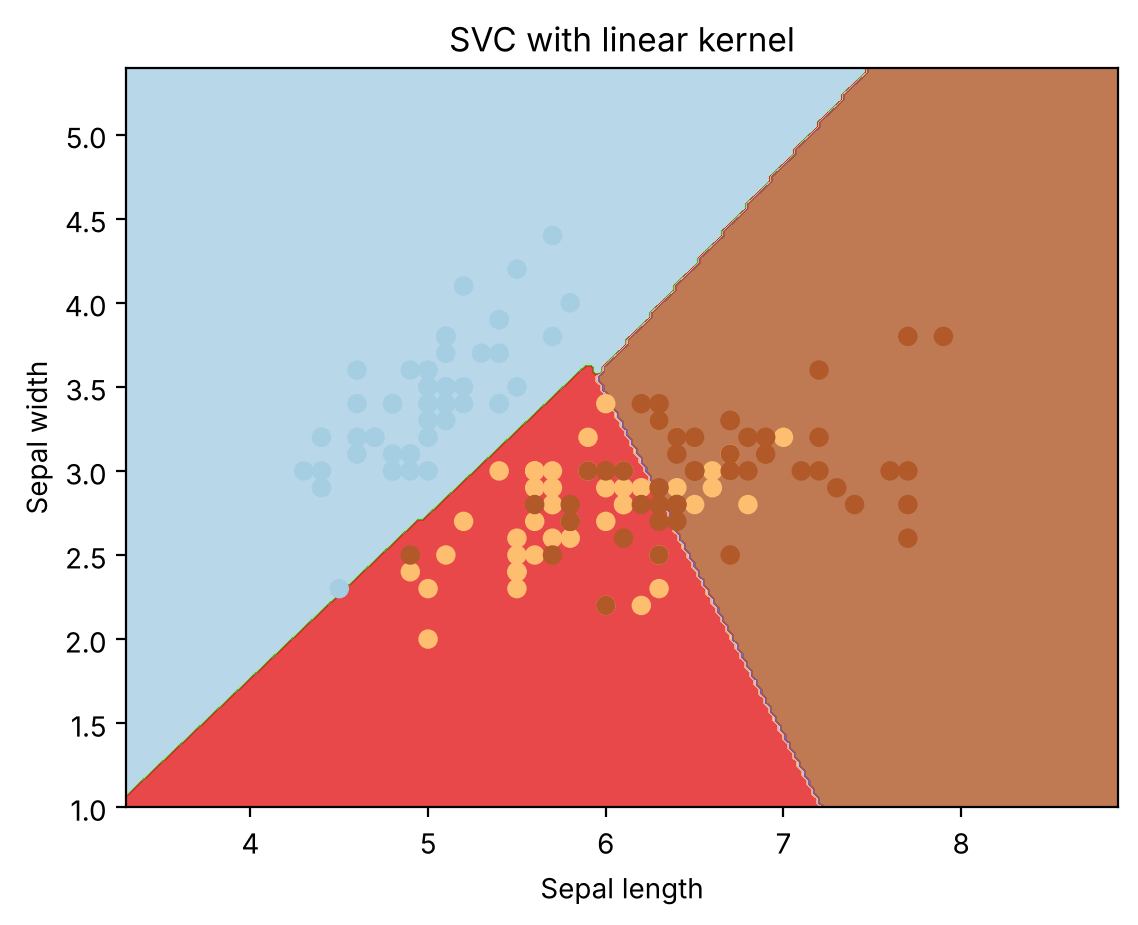

In [2]:
# create a mesh to plot
x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
h = (x_max / x_min)/100
xx, yy = np.meshgrid(np.arange(x_min, x_max, h),
         np.arange(y_min, y_max, h))
  
# Plot the data for Proper Visual Representation
plt.subplot(1, 1, 1)
  
# Predict the result by giving Data to the model
Z = svc.predict(np.c_[xx.ravel(), yy.ravel()])
Z = Z.reshape(xx.shape)
plt.contourf(xx, yy, Z, cmap = plt.cm.Paired, alpha = 0.8)
  
plt.scatter(X[:, 0], X[:, 1], c = y, cmap = plt.cm.Paired)
plt.xlabel('Sepal length')
plt.ylabel('Sepal width')
plt.xlim(xx.min(), xx.max())
plt.title('SVC with linear kernel')
  
# Output the Plot
plt.show()

## Activities

<ul>
    <li>Try other data splitting methods and see how it affects the results.</li>
    <li>Use the evaluation metrics for classification to report the results.</li>
    <li>Change the C parameter to obtain the best possible results.</li>  
    <li>Try non-linear kernels on this dataset (Gaussian Radial Basis Function Kernel, Sigmoid Kernel, Polynomial Kernel ... )</li>
</ul>

### Activité 1 — Autres méthodes de découpage des données

Le modèle est entraîné sur les 2 premières variables (longueur et largeur du sépale), comme dans le lab. On compare : hold-out 70/30 non stratifié, hold-out stratifié, hold-out 80/20, K-Fold (5 plis, sans mélange), K-Fold mélangé, Stratified K-Fold, Leave-One-Out et validation croisée répétée.

In [3]:
import pandas as pd
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, LeaveOneOut,
                                     RepeatedStratifiedKFold, cross_val_score)

def holdout(test_size, stratify, seed):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=test_size, random_state=seed,
                                          stratify=y if stratify else None)
    return svm.SVC(kernel='linear', C=1).fit(Xtr, ytr).score(Xte, yte)

res = {}
res['Hold-out 70/30 (non stratifié)']  = [holdout(.3, False, s) for s in range(20)]
res['Hold-out 70/30 (stratifié)']      = [holdout(.3, True,  s) for s in range(20)]
res['Hold-out 80/20 (stratifié)']      = [holdout(.2, True,  s) for s in range(20)]
print('Hold-out : moyenne et écart-type sur 20 graines différentes')
for k, v in res.items():
    print('  %-32s moyenne=%.3f  écart-type=%.3f  min=%.3f  max=%.3f' % (k, np.mean(v), np.std(v), min(v), max(v)))

print('\nValidation croisée (accuracy moyenne) :')
cvs = {
 'KFold 5 (sans mélange)'      : KFold(5),
 'KFold 5 (mélangé)'           : KFold(5, shuffle=True, random_state=0),
 'StratifiedKFold 5'           : StratifiedKFold(5, shuffle=True, random_state=0),
 'StratifiedKFold 10'          : StratifiedKFold(10, shuffle=True, random_state=0),
 'Leave-One-Out'               : LeaveOneOut(),
 'RepeatedStratifiedKFold 5x10': RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0),
}
for k, cv in cvs.items():
    s = cross_val_score(svm.SVC(kernel='linear', C=1), X, y, cv=cv)
    print('  %-30s moyenne=%.3f  écart-type=%.3f  (nb plis=%d)' % (k, s.mean(), s.std(), len(s)))

Hold-out : moyenne et écart-type sur 20 graines différentes
  Hold-out 70/30 (non stratifié)   moyenne=0.793  écart-type=0.057  min=0.667  max=0.889
  Hold-out 70/30 (stratifié)       moyenne=0.803  écart-type=0.049  min=0.711  max=0.889
  Hold-out 80/20 (stratifié)       moyenne=0.802  écart-type=0.056  min=0.700  max=0.867

Validation croisée (accuracy moyenne) :
  KFold 5 (sans mélange)         moyenne=0.613  écart-type=0.309  (nb plis=5)
  KFold 5 (mélangé)              moyenne=0.793  écart-type=0.083  (nb plis=5)
  StratifiedKFold 5              moyenne=0.793  écart-type=0.025  (nb plis=5)
  StratifiedKFold 10             moyenne=0.787  écart-type=0.072  (nb plis=10)


  Leave-One-Out                  moyenne=0.800  écart-type=0.400  (nb plis=150)
  RepeatedStratifiedKFold 5x10   moyenne=0.805  écart-type=0.055  (nb plis=50)


#### Remarques

- Avec les **2 premières variables** seulement, l'accuracy est de l'ordre de **80 %** (contre ≈ 98 % avec les 4 variables) : le sépale seul ne permet pas de bien distinguer *versicolor* et *virginica*.
- **Hold-out** : le résultat dépend beaucoup de la graine (écart-type ≈ 5 points ; de 67 % à 89 % selon le découpage). Le découpage stratifié donne une moyenne un peu plus élevée et plus stable que le non stratifié, car il conserve la proportion des 3 classes.
- **KFold sans mélange : 61 % ± 31 %**, un très mauvais résultat. Le jeu iris est **trié par classe** (50 setosa, puis 50 versicolor, puis 50 virginica) : chaque pli contient presque une seule classe, et le modèle est testé sur une classe qu'il n'a jamais vue à l'entraînement. Il faut donc **mélanger** (`shuffle=True`) ou utiliser `StratifiedKFold`.
- **StratifiedKFold** et **KFold mélangé** donnent ≈ 79 %, avec l'écart-type le plus faible pour StratifiedKFold 5 (0.025). **Leave-One-Out** (80 %) est coûteux (150 entraînements) et son écart-type de 0.4 n'a pas de sens (chaque « score » vaut 0 ou 1). La VC répétée (80.5 %) donne l'estimation la plus stable.
- **Conclusion** : on privilégie une validation croisée **stratifiée et mélangée**, éventuellement répétée, plutôt qu'un seul hold-out.

### Activité 2 — Métriques d'évaluation

Trois classes : on utilise la matrice de confusion et les métriques par classe (précision, rappel, F1) sur un jeu de test stratifié (30 %), avec le modèle linéaire `C=1`.

Accuracy test : 0.756
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.62      0.67      0.65        15
   virginica       0.64      0.60      0.62        15

    accuracy                           0.76        45
   macro avg       0.76      0.76      0.76        45
weighted avg       0.76      0.76      0.76        45



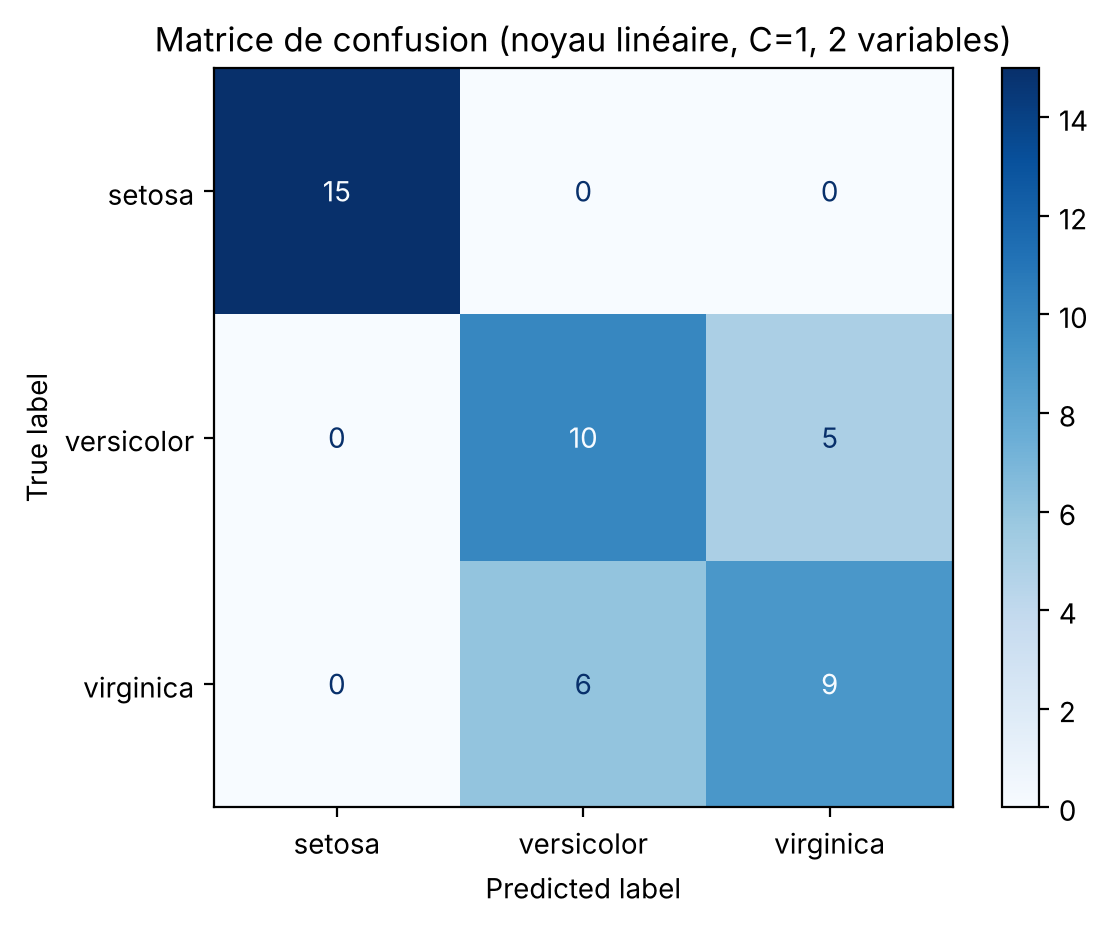

In [4]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, accuracy_score

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
model = svm.SVC(kernel='linear', C=1).fit(Xtr, ytr)
yp = model.predict(Xte)
print('Accuracy test : %.3f' % accuracy_score(yte, yp))
print(classification_report(yte, yp, target_names=iris.target_names))
ConfusionMatrixDisplay.from_predictions(yte, yp, display_labels=iris.target_names, cmap='Blues')
plt.title('Matrice de confusion (noyau linéaire, C=1, 2 variables)'); plt.show()

#### Interprétation

- Accuracy test = **75.6 %** (34 / 45). *Setosa* est parfaitement classée (précision = rappel = 1.00) : elle est linéairement séparable des deux autres avec ces 2 variables.
- *Versicolor* (F1 = 0.65) et *virginica* (F1 = 0.62) sont **confondues entre elles** : leurs nuages de points se chevauchent dans le plan (longueur, largeur du sépale). C'est la limite des 2 variables choisies, pas du noyau (voir Activité 4 : aucun noyau n'améliore nettement le résultat).
- Les métriques par classe sont plus informatives que l'accuracy globale, qui masque le fait que le modèle est parfait sur une classe et médiocre sur les deux autres.

### Activité 3 — Choix du paramètre C

On teste C de 10⁻³ à 10³ en validation croisée stratifiée répétée (5×10). Le nombre de vecteurs supports montre l'effet de C sur la marge.

,accuracy CV,écart-type,nb vecteurs supports
C,,,
0.001000,0.7613,0.0620,150
0.003162,0.7613,0.0620,150
0.010000,0.7613,0.0620,150
0.031623,0.7820,0.0542,137
0.100000,0.7960,0.0484,115
0.316228,0.8093,0.0525,96
1.000000,0.8053,0.0551,81
3.162278,0.7987,0.0525,76
10.000000,0.7967,0.0526,75


Meilleur C : 0.3162  (accuracy CV = 0.8093)


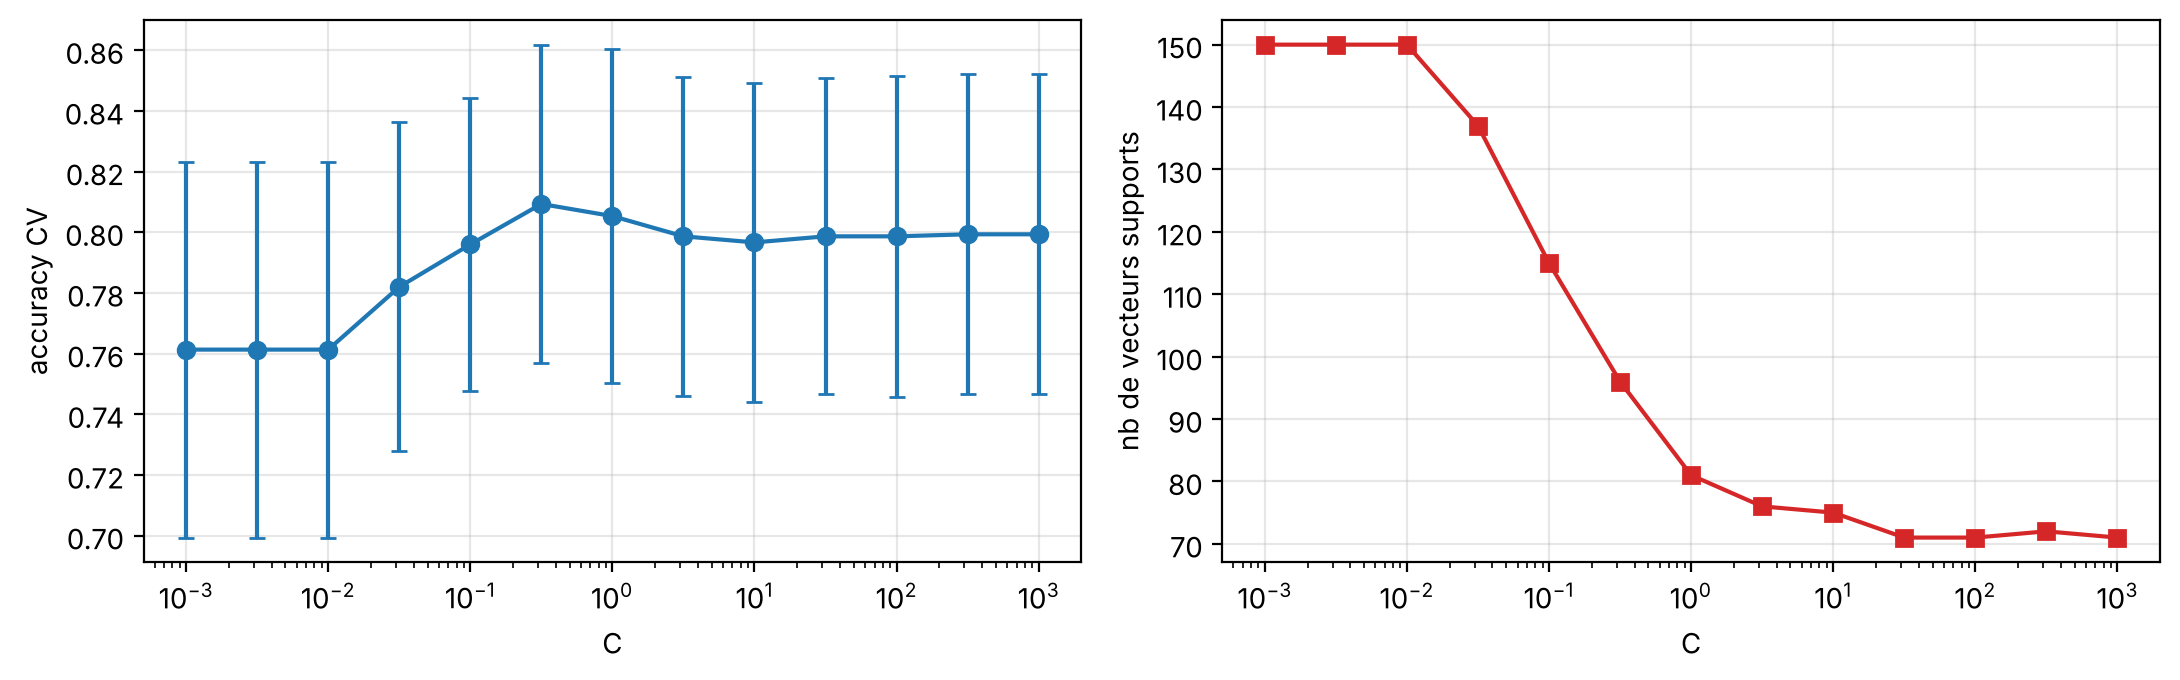

In [5]:
Cs = np.logspace(-3, 3, 13)
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
cv_m, cv_s, nsv = [], [], []
for Cv in Cs:
    m = svm.SVC(kernel='linear', C=Cv)
    s = cross_val_score(m, X, y, cv=rcv)
    cv_m.append(s.mean()); cv_s.append(s.std()); nsv.append(m.fit(X, y).n_support_.sum())
tab = pd.DataFrame({'C': Cs, 'accuracy CV': cv_m, 'écart-type': cv_s, 'nb vecteurs supports': nsv}).set_index('C')
display(tab.round(4))
best_C = Cs[int(np.argmax(cv_m))]
print('Meilleur C : %.4g  (accuracy CV = %.4f)' % (best_C, max(cv_m)))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].errorbar(Cs, cv_m, yerr=cv_s, fmt='o-', capsize=3); ax[0].set_xscale('log'); ax[0].set_xlabel('C'); ax[0].set_ylabel('accuracy CV'); ax[0].grid(alpha=.3)
ax[1].plot(Cs, nsv, 's-', c='tab:red'); ax[1].set_xscale('log'); ax[1].set_xlabel('C'); ax[1].set_ylabel('nb de vecteurs supports'); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

#### Remarques

- Pour **C très petit** (≤ 0.01), la marge est très large et tous les points sont vecteurs supports (150) : le modèle **sous-apprend** (76 %).
- L'accuracy CV augmente jusqu'à **C ≈ 0.3 (80.9 %)** puis se stabilise vers 80 % ; le nombre de vecteurs supports diminue de 150 à ≈ 71 quand C augmente (marge plus étroite, erreurs moins tolérées).
- Au-delà de C ≈ 1, la courbe est **plate** : les données (2 variables) ne sont pas séparables linéairement, donc augmenter C ne sert à rien. Les différences entre C = 0.3 et C = 1 (80.9 % contre 80.5 %) sont **bien plus petites que l'écart-type (≈ 5 points)** : on peut choisir indifféremment **C entre 0.3 et 1**. On retient C = 0.3 (meilleur score), tout en notant qu'il s'agit d'un gain marginal.
- Un C trop grand peut devenir risqué : le modèle essaie de classer correctement chaque point d'entraînement, y compris les points bruités.

### Activité 4 — Noyaux non linéaires (RBF, sigmoïde, polynomial)

Frontières de décision sur les 2 variables, avec les scores de validation croisée correspondants.

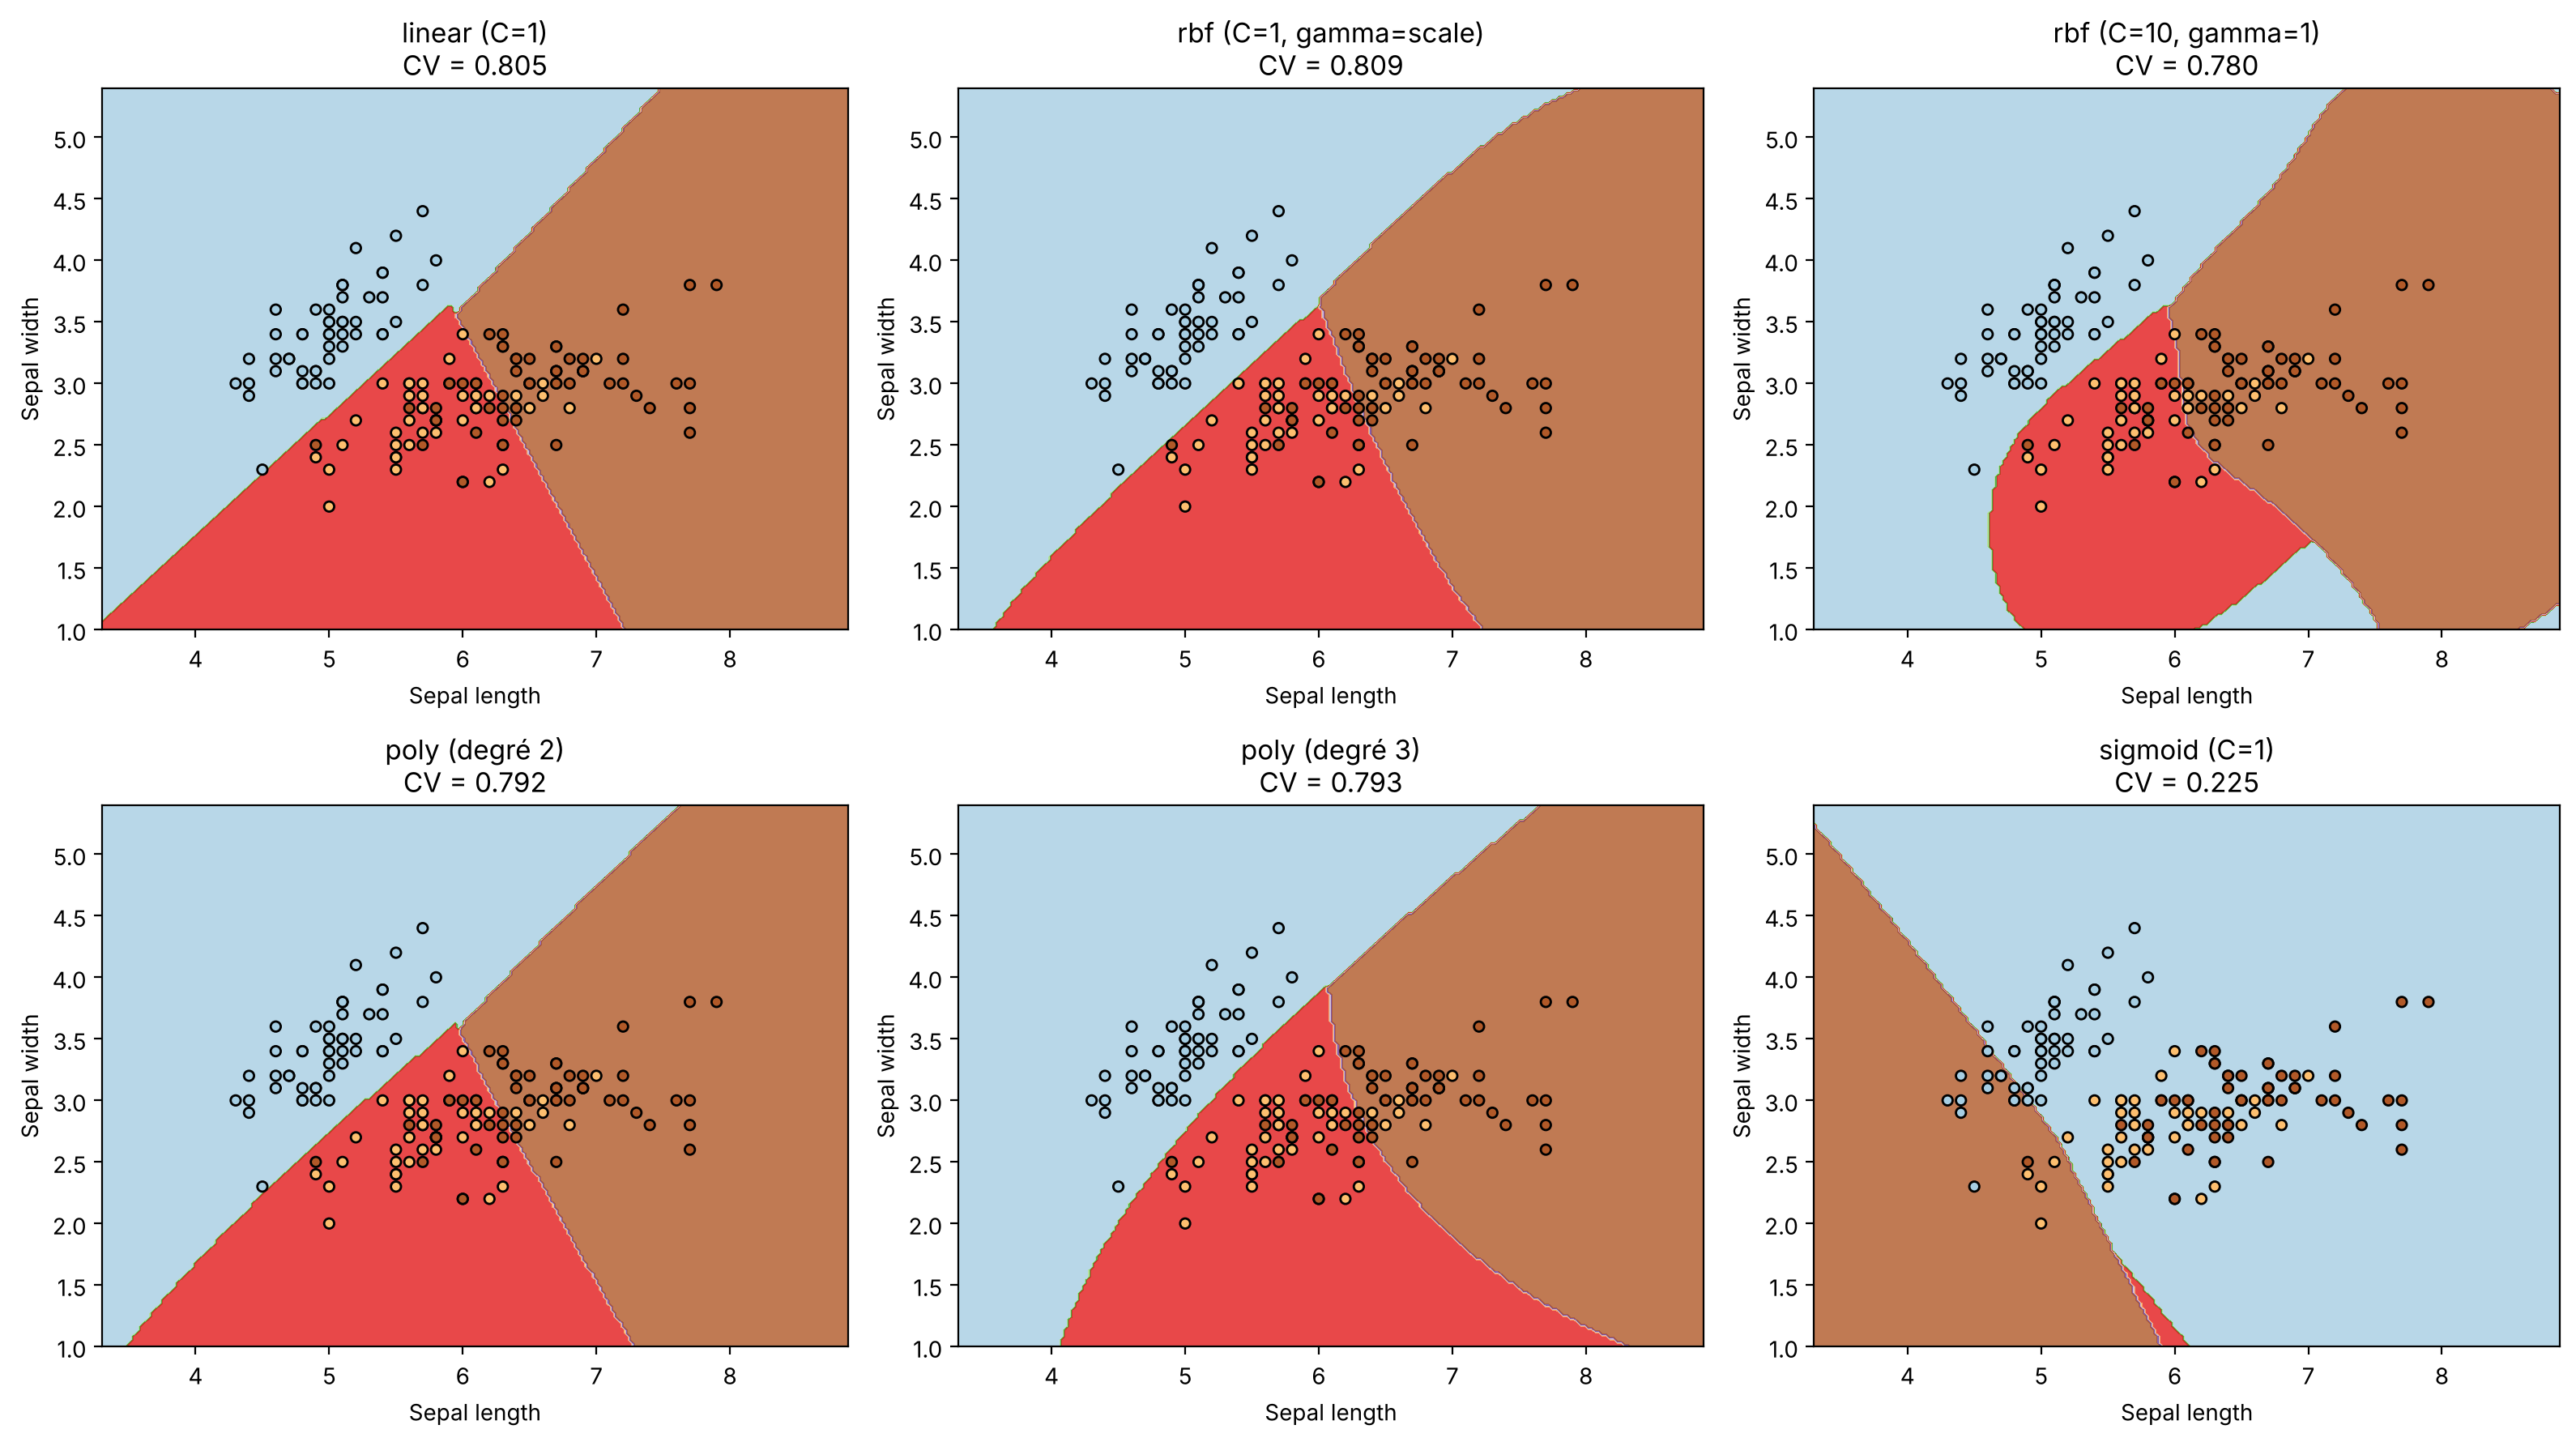

,train,CV,ecart_type,vecteurs_supports
noyau,,,,
linear (C=1),0.820,0.805,0.055,81
"rbf (C=1, gamma=scale)",0.820,0.809,0.050,94
"rbf (C=10, gamma=1)",0.813,0.780,0.062,74
poly (degré 2),0.820,0.792,0.052,77
poly (degré 3),0.813,0.793,0.049,70
sigmoid (C=1),0.247,0.225,0.062,150


In [6]:
kernels = {
 'linear (C=1)'          : svm.SVC(kernel='linear', C=1),
 'rbf (C=1, gamma=scale)': svm.SVC(kernel='rbf', C=1),
 'rbf (C=10, gamma=1)'   : svm.SVC(kernel='rbf', C=10, gamma=1),
 'poly (degré 2)'        : svm.SVC(kernel='poly', degree=2),
 'poly (degré 3)'        : svm.SVC(kernel='poly', degree=3),
 'sigmoid (C=1)'         : svm.SVC(kernel='sigmoid', C=1),
}
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
rows = []
for ax, (name, m) in zip(axes.ravel(), kernels.items()):
    m.fit(X, y)
    Zg = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Zg, cmap=plt.cm.Paired, alpha=.8)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.Paired, edgecolor='k', s=20)
    s = cross_val_score(m, X, y, cv=rcv)
    ax.set_title('%s\nCV = %.3f' % (name, s.mean())); ax.set_xlabel('Sepal length'); ax.set_ylabel('Sepal width')
    rows.append(dict(noyau=name, train=m.score(X, y), CV=s.mean(), ecart_type=s.std(), vecteurs_supports=int(m.n_support_.sum())))
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index('noyau').round(3))

On refait la comparaison avec les **4 variables** de l'iris (non seulement les 2 premières) pour voir l'effet de l'information disponible.

In [7]:
X4 = iris.data
rows = []
for name, m in kernels.items():
    s2 = cross_val_score(m, X, y, cv=rcv).mean()
    s4 = cross_val_score(m, X4, y, cv=rcv).mean()
    rows.append(dict(noyau=name, **{'2 variables (CV)': s2, '4 variables (CV)': s4}))
display(pd.DataFrame(rows).set_index('noyau').round(3))

,2 variables (CV),4 variables (CV)
noyau,,
linear (C=1),0.805,0.977
"rbf (C=1, gamma=scale)",0.809,0.963
"rbf (C=10, gamma=1)",0.780,0.953
poly (degré 2),0.792,0.973
poly (degré 3),0.793,0.960
sigmoid (C=1),0.225,0.069


#### Remarques

- **Avec 2 variables**, linéaire (80.5 %), RBF (80.9 %), poly 2 (79.2 %) et poly 3 (79.3 %) sont **équivalents** (écarts ≪ écart-type de 5 points) : les frontières non linéaires ne règlent pas le chevauchement entre *versicolor* et *virginica*. Le RBF avec `C=10, gamma=1` (78 %) a une frontière plus tortueuse qui s'adapte au bruit : début de surapprentissage.
- Le noyau **sigmoïde** donne ≈ 22 % (moins que le hasard) : les variables n'étant pas normalisées, il n'est pas utilisable tel quel.
- **Avec les 4 variables**, tous les noyaux sauf le sigmoïde montent à **95–98 %** : l'information disponible compte beaucoup plus que le choix du noyau. Le noyau linéaire est encore le meilleur (97.7 %).
- **Conclusion** : commencer par le noyau linéaire ; ne passer à RBF/poly que si la validation croisée montre un vrai gain.